In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [4]:
df=pd.read_csv("/content/creditcard.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\n Class Distribution:")
print(df["Class"].value_counts())

print("\nCategory percentages:")
print(df["Class"].value_counts(normalize=True)*100)

Dataset loaded successfully!
Dataset shape: (5974, 31)

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0     0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1     0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2     1 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3     1 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4     2 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798

In [5]:
X=df.drop("Class",axis=1)
y=df["Class"]
print("Feature shape:",X.shape)
print("Target shape:",y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (5974, 30)
Target shape: (5974,)

Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [6]:
df_clean = df.dropna()
X_clean = df_clean.drop("Class", axis=1)
y_clean = df_clean["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4778, 30)
Testing data: (1195, 30)


In [7]:
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
print("Training Random FOrest model...")
model.fit(X_train,y_train)
print("Model training completed successfully!")

Training Random FOrest model...
Model training completed successfully!


In [8]:
y_pred=model.predict(X_test)
y_prob=model.predict_proba(X_test)[:,1]
print("Actual labels:")
print(y_test.head(20))
print(("Predicted labels:"))
print(y_pred[:20])

Actual labels:
4582    0.0
1344    0.0
2597    0.0
5951    0.0
2118    0.0
2818    0.0
2816    0.0
1972    0.0
5748    0.0
5831    0.0
202     0.0
5045    0.0
2484    0.0
1518    0.0
1486    0.0
5453    0.0
201     0.0
5708    0.0
3509    0.0
126     0.0
Name: Class, dtype: float64
Predicted labels:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1194    0]
 [   1    0]]


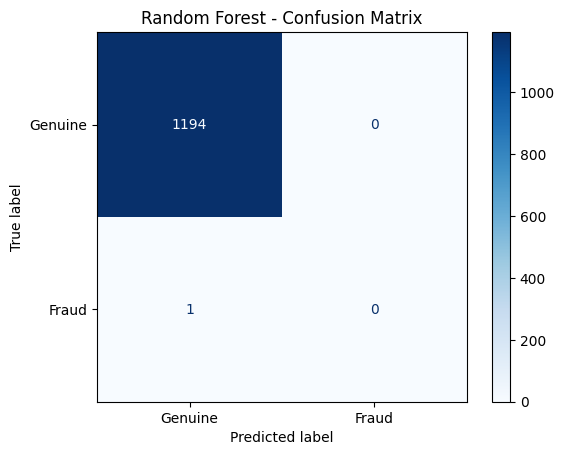

Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
ROC-AUC   : 0.9966

Detailed Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00      1194
       Fraud       0.00      0.00      0.00         1

    accuracy                           1.00      1195
   macro avg       0.50      0.50      0.50      1195
weighted avg       1.00      1.00      1.00      1195



In [10]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.show()

precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, zero_division=0
)
roc_auc = roc_auc_score(y_test, y_prob)
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

In [11]:
results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred
results["Fraud_Probability"] = y_prob

actual_fraud = results[results["Actual"] == 1]

print("Total actual fraud cases:", len(actual_fraud))
print(actual_fraud[["Time", "Amount", "Actual", "Predicted", "Fraud_Probability"]].head(20))

print("Fraud detected:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 1)]))
print("Fraud missed:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 0)]))

actual_fraud.to_csv("actual_fraudulent_test_transactions.csv", index=True)
print("File saved successfully!")


Total actual fraud cases: 1
      Time  Amount  Actual  Predicted  Fraud_Probability
4920  4462  239.93     1.0        0.0               0.03
Fraud detected: 0
Fraud missed: 1
File saved successfully!


Top 10 Important Features:
V14     0.210641
V1      0.138572
Time    0.072656
V23     0.068705
V9      0.057307
V6      0.054838
V21     0.048017
V15     0.046603
V17     0.045187
V4      0.037803
dtype: float64


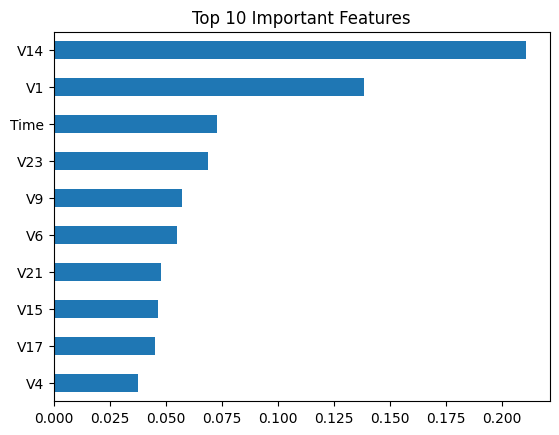

In [12]:
importance = pd.Series(model.feature_importances_, index=X.columns)

top10 = importance.nlargest(10)
print("Top 10 Important Features:")
print(top10)

top10.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()


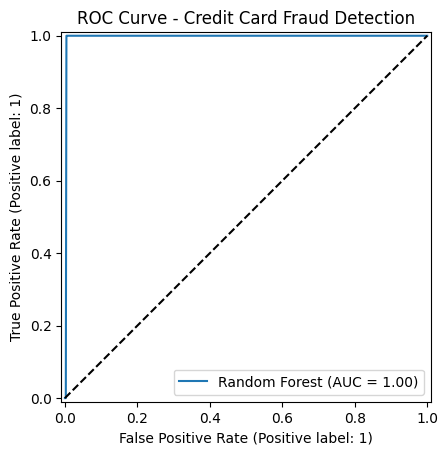

In [13]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)
plt.title("ROC Curve - Credit Card Fraud Detection")
plt.plot([0, 1], [0, 1], "k--")
plt.show()